# 05. Обучение на смесях опухоли и нормальной ткани

**Откуда идея.** В ноутбуке 04 нормальные ткани как отдельный класс не помогли: модель всё так же называла метастаз рака груди в печени «раком печени». Причина в том, что модель ни разу не видела **смесь** опухоли и чужого органа. Значит, надо ей эти смеси показать.

**Как делаем смесь.** Биопсия метастаза — это опухолевые клетки плюс нормальные клетки органа. Клетки смешиваются по количеству РНК, а не по логарифмам, поэтому смешиваем в линейной шкале:

$$x_\text{смесь} = \log_2\big((1-a)\cdot\text{опухоль} + a\cdot\text{норма} + 1\big)$$

где $a$ — доля нормальной ткани. Метка остаётся меткой опухоли: «рак груди + 30% печени» — это по-прежнему рак груди.

**Дизайн (зафиксирован до просмотра результатов):**
- каждой опухоли из обучающей выборки TCGA добавляется одна копия, смешанная со случайным образцом GTEx (любая из 26 тканей, только доноры из обучающей части), $a \sim U(0.1,\ 0.6)$;
- те же 15 629 генов и те же настройки, что у модели «только опухоли»;
- проверка, не трогающая MET500: опухоли из **валидационной** выборки, смешанные с нормальными тканями **отложенных** доноров GTEx;
- MET500 используется только для итогового сравнения.

Расчёт: `src/mixtures.py`.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

R = "../results"
mx = json.load(open(f"{R}/mixtures.json"))

## Проверка на искусственных смесях (без MET500)

Сначала убедимся, что модель вообще научилась тому, чему мы хотели: валидационные опухоли смешиваем с нормальными тканями доноров, которых не было в обучении.

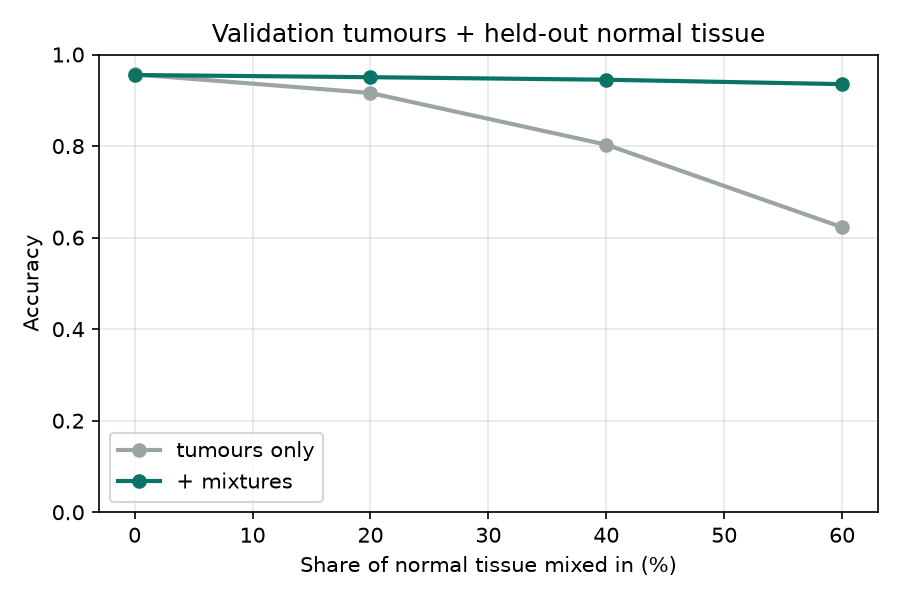

model,tumours_only,with_mixtures
normal_share,,
0.0,0.957,0.955
0.2,0.916,0.950
0.4,0.803,0.945
0.6,0.623,0.935


In [2]:
display(Image(f"{R}/figures/mixtures_synthetic.png", width=600))
pd.DataFrame(mx["synthetic_check"]).pivot(index="normal_share", columns="model", values="accuracy").round(3)

Обычная модель быстро теряет точность: при 60% нормальной ткани остаётся 62%. Модель, обученная на смесях, держит 93–95% при любой доле. На чистых опухолях (0%) обе одинаковы, то есть смеси ничего не испортили.

Оговорка: эта проверка оптимистична, потому что искусственные смеси сделаны тем же способом, что и обучающие. Настоящий экзамен — реальные метастазы.

## Реальные метастазы MET500

In [3]:
rows = []
for name, r in mx["models"].items():
    rows.append({"модель": "только опухоли" if name == "tumours_only" else "+ смеси",
                 "тест TCGA": round(r["tcga_test"]["accuracy"], 3),
                 "CPTAC-3": round(r["cptac3"]["accuracy"], 3),
                 "MET500": round(r["met500"]["accuracy"], 3),
                 "MET500 топ-3": round(r["met500"]["top3_accuracy"], 3),
                 "метастазы в печени → LIHC": r["met500_liver_called_LIHC"]})
pd.DataFrame(rows)

,модель,тест TCGA,CPTAC-3,MET500,MET500 топ-3,метастазы в печени → LIHC
0,только опухоли,0.97,0.908,0.664,0.817,41
1,+ смеси,0.97,0.907,0.696,0.815,16


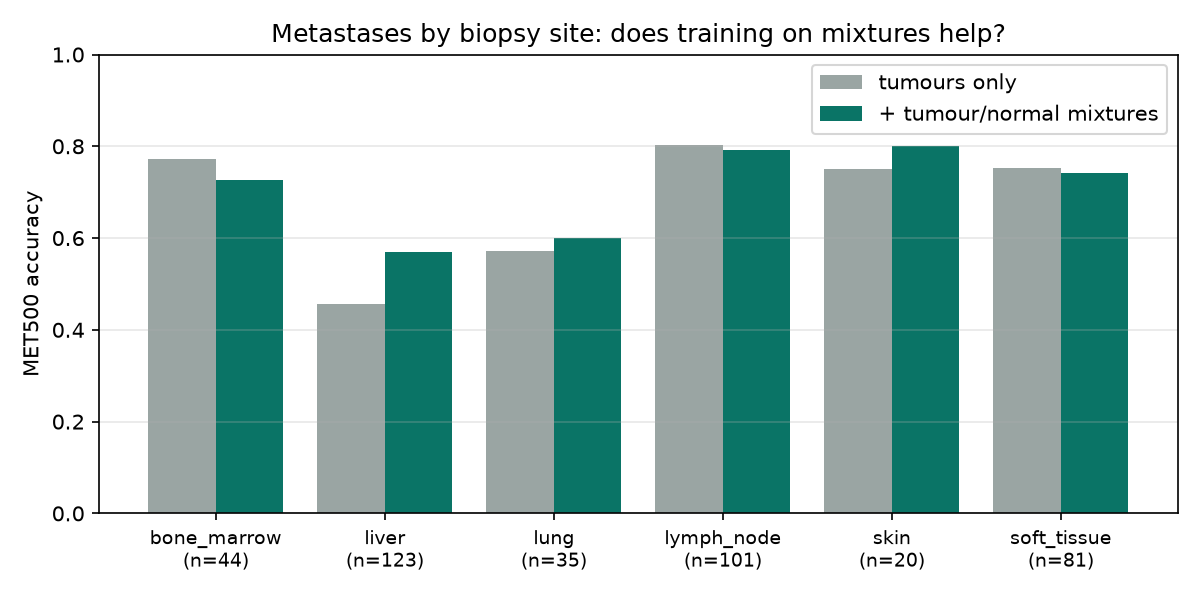

{'only_first_correct': 15,
 'only_second_correct': 29,
 'p_value': 0.048766765904474596}

In [4]:
display(Image(f"{R}/figures/mixtures_met500.png", width=800))
mx["met500_paired_test"]

**Что видно:**

- **Точность на MET500 выросла: 66.4% → 69.6%.** Метастазов в печени, названных раком печени, стало **в 2.5 раза меньше: 41 → 16**. Точность на биопсиях печени выросла с 46% до 57%.
- На первичных опухолях ничего не изменилось (TCGA 97.0%, CPTAC-3 90.7–90.8%): смеси не мешают обычной задаче.
- **Значимость.** Модели расходятся на 44 пациентах: новая права в 29 случаях, старая в 15. Точный тест Макнемара даёт p = 0.049, то есть улучшение на грани статистической значимости. Это честный, но скромный выигрыш, а не прорыв.
- В некоторых органах (костный мозг, лимфоузлы) стало чуть хуже, но там пациентов мало, и разница в 1–2 человека.
- Топ-3 почти не изменился (81.7% → 81.5%): правильный ответ и раньше часто был среди трёх вариантов, а теперь чаще стоит на первом месте.

### Почему это сработало, а фоновый класс — нет

Фоновый класс учил модель отличать рак печени от *нормальной* печени, но в сравнении «рак печени против рака груди» печёночные гены всё равно голосовали за рак печени. Смеси меняют сами обучающие примеры: модель видит рак груди с высокими печёночными генами и меткой «рак груди». Поэтому вес печёночных генов в пользу рака печени уменьшается, и модель учится опираться на гены самой опухоли.

## Итог всех экспериментов с метастазами

| Модель | MET500 | Метастазы в печени → LIHC | TCGA тест | CPTAC-3 |
|---|---|---|---|---|
| Только опухоли | 0.664 | 41 | 0.970 | 0.908 |
| + нормальные ткани как классы (ноутбук 04) | 0.629 | 41 | 0.972 | 0.926 |
| **+ смеси опухоль/норма** | **0.696** | **16** | 0.970 | 0.907 |

**Что можно попробовать дальше:** подобрать долю нормальной ткани и число смесей на валидации (сейчас взято одно разумное значение, без подбора), смешивать с несколькими тканями сразу, применить к модели LightGBM, проверить на других наборах метастазов. Любой подбор надо делать на искусственных смесях или на валидации, а MET500 оставить для финальной проверки, иначе мы начнём подгонять модель под тест.